# Journal 5 - Final evaluation on the test sets

**Question.** Does the champion hold on tickets written by another model, and is D-q4 still the right choice?
**Answer.** On `test_natural`, D-q4 makes **0.7 silent errors per 100 tickets against 33.9 for B2**, with 0.6 % of urgent tickets in a wrong desk (1 of 167) against 6.6 %. On the traps it is at 1.3 per 100 against 58.7. It meets the first-pass routing and auto-routing component bars; the urgent guardrail fails on the model alone. The prompted base model B3 (same Qwen 3B, no fine-tuning) makes 10.5 silent errors per 100, but 40 % of its answers break the JSON contract, so it routes only 43 % of tickets by itself and hands 43 in 100 to a person without need. D-q4 is registered in the Vertex AI Model Registry.

Each system is scored **once** (`docs/scoring_protocol.md`). Nothing was tuned after reading. B3 test predictions come from separate inference runs on the same frozen splits; the choice of D-q4 rests on val.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import _viz as viz
import _tracking
viz.setup()

from src import scoring
R = ROOT / "docs/results"
SYSTEMS = {"B0": "b0", "B1": "b1", "B2": "b2", "B3": "b3", "D": "d_gpu", "D-q8": "d_q8", "D-q4": "d_q4"}
NAMES = viz.LABELS
def fallback(system, split):
    if system == "B3":
        return ROOT / "data/runs" / f"base_{split}_predictions.csv"
    return R / f"{SYSTEMS[system]}_{split}_predictions.csv"
def raw(system, split):
    tickets, _, _ = scoring.load_split(ROOT / "data/dataset" / f"{split}.csv")
    values = _tracking.load_predictions(ROOT, system, split, fallback(system, split), tickets)
    if values is None:
        raise FileNotFoundError(f"No tracked or local predictions for {system}/{split}")
    return values
def systems_for(split):
    tickets, _, _ = scoring.load_split(ROOT / "data/dataset" / f"{split}.csv")
    return [system for system in SYSTEMS if _tracking.has_predictions(ROOT, system, split, fallback(system, split), len(tickets))]

## 1. Headline: `test_natural` (610 tickets)


[!] MLFLOW TRACKING NOTICE: Server unreachable at: http://127.0.0.1:5000
    (Connectivity check timed out in 0.1s to prevent notebook freeze)

    -> Local fallback active: reading predictions and metrics directly
       from local CSV files in `docs/results/`.

    INFO: To start the local MLflow server and enable live tracking:
       1. Open a separate terminal
       2. Run: mlflow server --host 127.0.0.1 --port 5000
          (or: uv run mlflow server --port 5000)

Using local historical prediction file: docs\results\b0_test_natural_predictions.csv
Using local historical prediction file: docs\results\b1_test_natural_predictions.csv
Using local historical prediction file: docs\results\b2_test_natural_predictions.csv


Using local historical prediction file: data\runs\base_test_natural_predictions.csv
Using local historical prediction file: docs\results\d_gpu_test_natural_predictions.csv
Using local historical prediction file: docs\results\d_q8_test_natural_predictions.csv
Using local historical prediction file: docs\results\d_q4_test_natural_predictions.csv


,B0,B1,B2,B3,D,D-q8,D-q4
silent_error_rate,0.785,0.403,0.339,0.105,0.020,0.010,0.007
needless_triage_rate,0.000,0.241,0.003,0.431,0.010,0.016,0.020
urgent_wrong_desk,0.778,0.335,0.066,0.060,0.012,0.006,0.006
auto_routed_rate,1.000,0.685,0.905,0.430,0.839,0.828,0.825
desk_accuracy,0.236,0.446,0.916,0.533,0.980,0.979,0.975
exact_transaction_id,0.648,0.895,0.895,0.570,0.980,0.975,0.975
exact_amount,0.633,0.802,0.802,0.557,0.985,0.982,0.979
severity_score,3.890,2.274,1.666,0.998,0.111,0.067,0.054
valid_json_rate,1.000,1.000,1.000,0.603,0.989,0.982,0.979


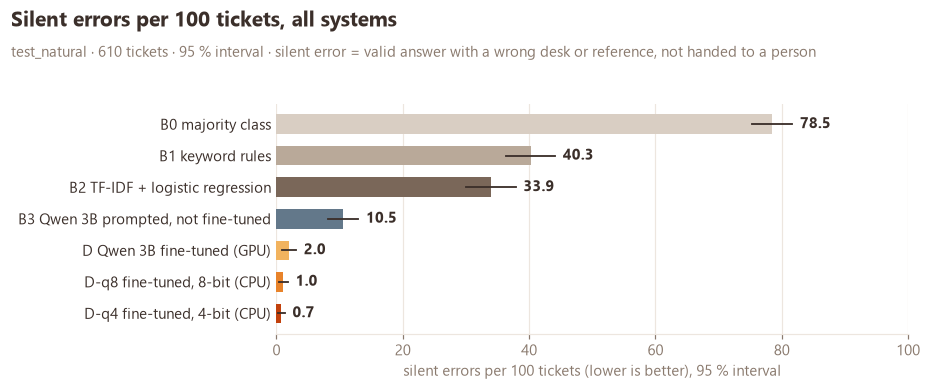

paired bootstrap vs B2 (difference per ticket, 95 % interval):


  D     silent errors -0.320 [-0.359, -0.280] | severity -1.554 [-1.756, -1.367]


  D-q8  silent errors -0.330 [-0.369, -0.290] | severity -1.598 [-1.798, -1.415]


  D-q4  silent errors -0.333 [-0.372, -0.295] | severity -1.611 [-1.811, -1.425]
silent errors of D-q4: 4 of 610 | urgent tickets: 167


In [2]:
_, nat_y, _ = scoring.load_split(ROOT / "data/dataset/test_natural.csv")
NATURAL_SYSTEMS = systems_for("test_natural")
nat = {s: scoring.score(nat_y, raw(s, "test_natural")) for s in NATURAL_SYSTEMS}
flags = {s: scoring.silent_errors(nat_y, raw(s, "test_natural")) for s in NATURAL_SYSTEMS}
ci = {s: scoring.mean_interval(f) for s, f in flags.items()}
n_urgent = sum(t.urgency == "high" for t in nat_y)
display(pd.DataFrame(nat).loc[["silent_error_rate", "needless_triage_rate", "urgent_wrong_desk", "auto_routed_rate", "desk_accuracy",
                               "exact_transaction_id", "exact_amount", "severity_score", "valid_json_rate"]].round(3))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
viz.hbar(ax, [NAMES[s] for s in NATURAL_SYSTEMS], [100 * ci[s][0] for s in NATURAL_SYSTEMS], [viz.SYSTEM_COLORS[s] for s in NATURAL_SYSTEMS],
         fmt="{:.1f}", errors=[(100 * ci[s][1], 100 * ci[s][2]) for s in NATURAL_SYSTEMS])
ax.set_xlim(0, 100); ax.set_xlabel("silent errors per 100 tickets (lower is better), 95 % interval")
viz.headline(fig, "Silent errors per 100 tickets, all systems", f"test_natural · 610 tickets · 95 % interval · {viz.SILENT}")
viz.save(fig, "05_test_silent")
plt.show()

print("paired bootstrap vs B2 (difference per ticket, 95 % interval):")
for s in (name for name in ("D", "D-q8", "D-q4") if name in NATURAL_SYSTEMS):
    ds = scoring.paired_bootstrap(flags[s], flags["B2"])
    dv = scoring.paired_bootstrap(scoring.severities(nat_y, raw(s, "test_natural")), scoring.severities(nat_y, raw("B2", "test_natural")))
    print(f"  {s:5} silent errors {ds[0]:+.3f} [{ds[1]:+.3f}, {ds[2]:+.3f}] | severity {dv[0]:+.3f} [{dv[1]:+.3f}, {dv[2]:+.3f}]")
print("silent errors of D-q4:", int(sum(flags["D-q4"])), "of", len(nat_y), "| urgent tickets:", n_urgent)

### Urgent failures across tested models
Counts use the same 167 reference `high` tickets. Wrong desk and missed urgency are separate events that may overlap.


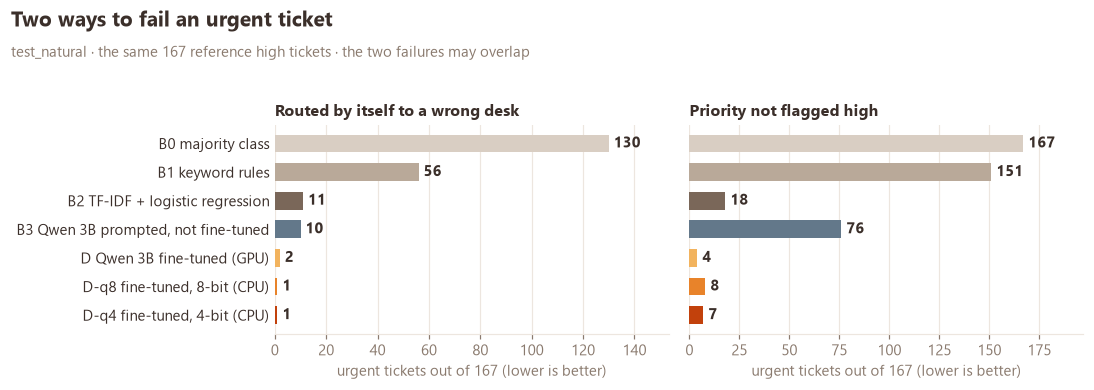

In [3]:
from src.router_evaluation import evaluate_router
urgent = {s: evaluate_router(nat_y, raw(s, 'test_natural'))['counts'] for s in NATURAL_SYSTEMS}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
colors = [viz.SYSTEM_COLORS[s] for s in NATURAL_SYSTEMS]
viz.hbar(axes[0], [NAMES[s] for s in NATURAL_SYSTEMS], [urgent[s]['high_wrong_desk_n'] for s in NATURAL_SYSTEMS], colors, fmt='{:.0f}')
viz.hbar(axes[1], [NAMES[s] for s in NATURAL_SYSTEMS], [urgent[s]['high_missed_n'] for s in NATURAL_SYSTEMS], colors, fmt='{:.0f}')
axes[1].set_yticklabels([])
axes[0].set_title('Routed by itself to a wrong desk', loc='left', fontsize=10.5)
axes[1].set_title('Priority not flagged high', loc='left', fontsize=10.5)
for ax in axes:
    ax.set_xlabel(f'urgent tickets out of {n_urgent} (lower is better)')
viz.headline(fig, 'Two ways to fail an urgent ticket', f'test_natural · the same {n_urgent} reference high tickets · the two failures may overlap')
viz.save(fig, '05_urgent_failure_modes')
plt.show()

## Router decision view (offline, same frozen predictions)

This diagnostic applies the initial desk/Re-router and priority rules to the predictions already loaded above. It does not change historical Qualifier gates. Production accuracy needs a separately verified sample.


,action accuracy,auto routed,needless Re-router,urgent wrong desk,urgent missed,urgent unknown,urgent Re-router
system,,,,,,,
B0,23.6%,100.0%,0,130/167,167/167,0,0
B1,44.6%,68.5%,147,56/167,151/167,0,50
B2,91.6%,90.5%,2,11/167,18/167,0,3
B3,53.3%,43.0%,263,10/167,76/167,56,77
D,98.0%,83.9%,6,2/167,4/167,3,13
D-q8,97.9%,82.8%,10,1/167,8/167,7,18
D-q4,97.5%,82.5%,12,1/167,7/167,7,18


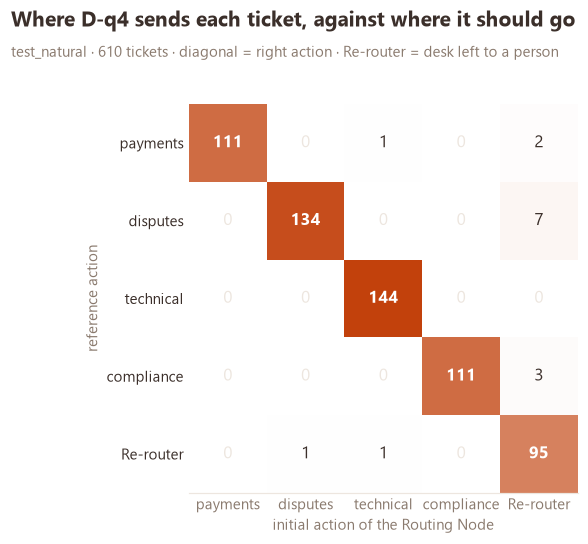

In [4]:
from src.router_evaluation import evaluate_router, DESKS
router_views = {s: evaluate_router(nat_y, raw(s, 'test_natural')) for s in NATURAL_SYSTEMS}
rows = []
for system, view in router_views.items():
    c, r = view['counts'], view['rates']
    rows.append({'system': system, 'action accuracy': r['action_accuracy'], 'auto routed': r['auto_routed_rate'],
                 'needless Re-router': c['needless_rerouter_n'], 'urgent wrong desk': f"{c['high_wrong_desk_n']}/{c['high_n']}",
                 'urgent missed': f"{c['high_missed_n']}/{c['high_n']}", 'urgent unknown': c['high_unknown_n'],
                 'urgent Re-router': c['high_rerouter_n']})
display(pd.DataFrame(rows).set_index('system').style.format({'action accuracy': '{:.1%}', 'auto routed': '{:.1%}'}))
shown = [d if d != 'triage' else 'Re-router' for d in DESKS]
matrix = pd.DataFrame(router_views['D-q4']['action_matrix']).T.loc[DESKS, DESKS]
fig, ax = plt.subplots(figsize=(6.6, 5))
ax.imshow(matrix.to_numpy(), cmap=LinearSegmentedColormap.from_list('theme', ['#FFFFFF', viz.SYSTEM_COLORS['D-q4']]))
ax.grid(False)
ax.set_xticks(range(len(DESKS)), shown); ax.set_yticks(range(len(DESKS)), shown)
ax.tick_params(length=0)
ax.set_xlabel('initial action of the Routing Node'); ax.set_ylabel('reference action')
top = matrix.to_numpy().max()
for i in range(len(DESKS)):
    for j in range(len(DESKS)):
        v = int(matrix.iloc[i, j])
        ax.text(j, i, v, ha='center', va='center', fontsize=11, fontweight='bold' if i == j else 'normal',
                color='white' if v > top / 2 else (viz.INK if v else viz.GRID))
viz.headline(fig, 'Where D-q4 sends each ticket, against where it should go', 'test_natural · 610 tickets · diagonal = right action · Re-router = desk left to a person')
viz.save(fig, '05_router_action_matrix')
plt.show()

The three fine-tuned variants beat B2 by about a third of the tickets, intervals far from 0, and keep urgent tickets in a wrong desk at or below 1.2 % (B2: 6.6 %). **D-q4 has the fewest silent errors (0.7 per 100) and the lowest severity score (0.054 against 1.666 points)**, even though it is the smallest. Its caution has a price: it hands 2 tickets in 100 to a human without need (D: 1). The prompted base model B3 sits between B2 and the fine-tuned models on silent errors, but it reaches that by failing the format: its invalid answers go to a person, so it routes fewer than half of the tickets by itself.

## 2. Stress test: `test_traps` (380 tickets, 23 trap families)
Only a diagnosis per family (counts, no intervals below 20 tickets). B2 vs the champion, families sorted by B2.

Using local historical prediction file: docs\results\b0_test_traps_predictions.csv
Using local historical prediction file: docs\results\b1_test_traps_predictions.csv
Using local historical prediction file: docs\results\b2_test_traps_predictions.csv
Using local historical prediction file: data\runs\base_test_traps_predictions.csv
Using local historical prediction file: docs\results\d_gpu_test_traps_predictions.csv
Using local historical prediction file: docs\results\d_q8_test_traps_predictions.csv
Using local historical prediction file: docs\results\d_q4_test_traps_predictions.csv


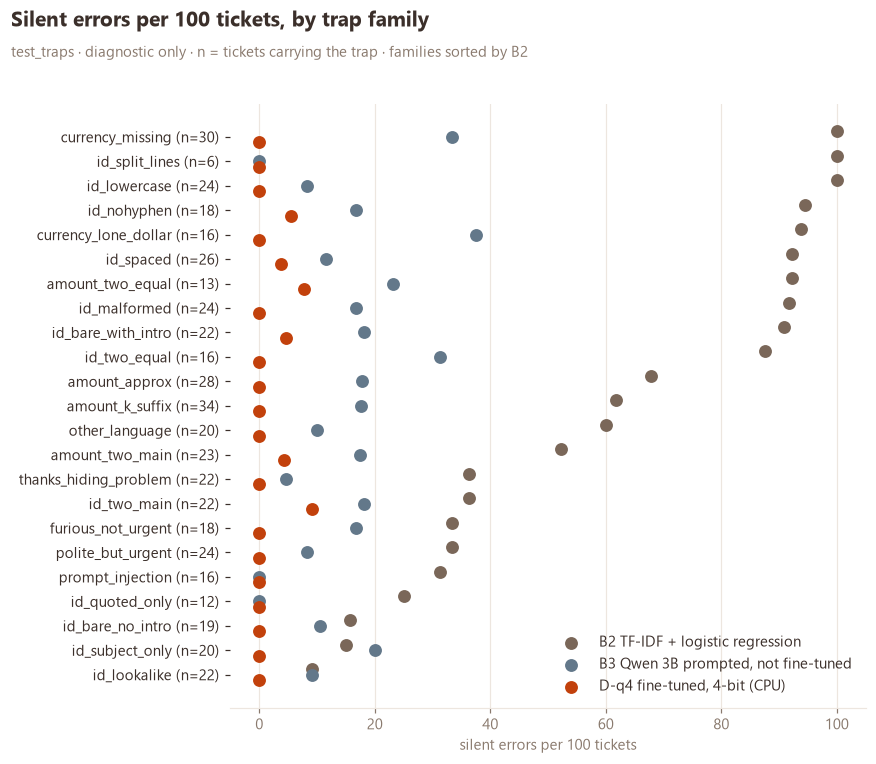

silent errors per 100 on test_traps: {'B0': 92.6, 'B1': 44.7, 'B2': 58.7, 'B3': 15.0, 'D': 1.3, 'D-q8': 1.3, 'D-q4': 1.3}
B2 families with a silent error (n, rate): {'amount_approx': {'n': 28.0, 'rate': 0.68}, 'amount_k_suffix': {'n': 34.0, 'rate': 0.62}, 'amount_two_equal': {'n': 13.0, 'rate': 0.92}, 'amount_two_main': {'n': 23.0, 'rate': 0.52}, 'currency_lone_dollar': {'n': 16.0, 'rate': 0.94}, 'currency_missing': {'n': 30.0, 'rate': 1.0}, 'furious_not_urgent': {'n': 18.0, 'rate': 0.33}, 'id_bare_no_intro': {'n': 19.0, 'rate': 0.16}, 'id_bare_with_intro': {'n': 22.0, 'rate': 0.91}, 'id_lookalike': {'n': 22.0, 'rate': 0.09}, 'id_lowercase': {'n': 24.0, 'rate': 1.0}, 'id_malformed': {'n': 24.0, 'rate': 0.92}, 'id_nohyphen': {'n': 18.0, 'rate': 0.94}, 'id_quoted_only': {'n': 12.0, 'rate': 0.25}, 'id_spaced': {'n': 26.0, 'rate': 0.92}, 'id_split_lines': {'n': 6.0, 'rate': 1.0}, 'id_subject_only': {'n': 20.0, 'rate': 0.15}, 'id_two_equal': {'n': 16.0, 'rate': 0.88}, 'id_two_main': {'n': 2

In [5]:
_, trap_y, trap_tags = scoring.load_split(ROOT / "data/dataset/test_traps.csv")
TRAP_SYSTEMS = systems_for("test_traps")
trap = {s: scoring.score(trap_y, raw(s, "test_traps")) for s in TRAP_SYSTEMS}
TRAP_COMPARE = [s for s in ("B2", "B3", "D-q4") if s in TRAP_SYSTEMS]
if not TRAP_COMPARE:
    raise ValueError("No complete test_traps predictions are available")
by = {s: pd.DataFrame(scoring.silent_by_trap(trap_y, raw(s, "test_traps"), trap_tags), index=["n", "rate"]).T for s in TRAP_COMPARE}
order_system = "B2" if "B2" in by else TRAP_COMPARE[0]
fam = by[order_system].sort_values("rate", ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
ys = np.arange(len(fam))
offsets = np.linspace(-0.22, 0.22, len(TRAP_COMPARE)) if len(TRAP_COMPARE) > 1 else [0]
for system, offset in zip(TRAP_COMPARE, offsets):
    rates = 100 * by[system].loc[fam.index, "rate"]
    ax.scatter(rates, ys + offset, color=viz.SYSTEM_COLORS[system], s=55, zorder=2, label=NAMES[system])
ax.set_yticks(ys, [f"{k} (n={int(n)})" for k, n in zip(fam.index, fam["n"])]); ax.invert_yaxis()
ax.grid(axis="y", visible=False); ax.set_xlabel("silent errors per 100 tickets"); ax.legend(loc="lower right")
viz.headline(fig, "Silent errors per 100 tickets, by trap family", "test_traps · diagnostic only · n = tickets carrying the trap · families sorted by B2")
viz.save(fig, "05_traps")
plt.show()

print("silent errors per 100 on test_traps:", {s: round(100 * trap[s]["silent_error_rate"], 1) for s in TRAP_SYSTEMS})
for system in TRAP_COMPARE:
    print(f"{system} families with a silent error (n, rate):", by[system][by[system]["rate"] > 0].round(2).to_dict("index"))

B2 makes silent errors on almost every ticket of the extraction families (missing currency, lowercase or spaced ids, two amounts). D-q4 is at or near 0 on most families; its few silent errors (4 to 9 tickets in 100 on 6 families) sit on ids and amounts written in odd ways (two amounts, spaced or hyphen-less ids). Malformed ids are mostly handed to a human by the contract, as seen on val in Journal 3. D (GPU) is a little more robust than D-q4 on the traps (fewer tickets handed to a human, more valid JSON), while `test_natural` favours D-q4: compression costs some robustness on odd ids.

## 3. Reading against the component acceptance bars
Historical Qualifier component bars.

In [6]:
bars = pd.DataFrame([
    ("First-pass routing: desk accuracy", ">= 90 %", f"{nat['D-q4']['desk_accuracy']:.1%}", f"{nat['B2']['desk_accuracy']:.1%}", nat["D-q4"]["desk_accuracy"] >= 0.90),
    ("Automatic routing: auto-routed rate", ">= 50 %", f"{nat['D-q4']['auto_routed_rate']:.1%}", f"{nat['B2']['auto_routed_rate']:.1%}", nat["D-q4"]["auto_routed_rate"] >= 0.50),
    ("Guardrail: urgent tickets in a wrong desk", "none", f"{nat['D-q4']['urgent_wrong_desk'] * n_urgent:.0f} of {n_urgent}", f"{nat['B2']['urgent_wrong_desk'] * n_urgent:.0f} of {n_urgent}", nat["D-q4"]["urgent_wrong_desk"] == 0),
], columns=["criterion", "bar", "D-q4", "B2", "D-q4 meets it"]).set_index("criterion")
bars

,bar,D-q4,B2,D-q4 meets it
criterion,,,,
First-pass routing: desk accuracy,>= 90 %,97.5%,91.6%,True
Automatic routing: auto-routed rate,>= 50 %,82.5%,90.5%,True
Guardrail: urgent tickets in a wrong desk,none,1 of 167,11 of 167,False


D-q4 and B2 both meet the first two component bars. D-q4 has fewer model-only silent errors, while its urgent wrong-desk guardrail fails (1 of 167).

## 4. All systems, all measures
Each panel is one measure on `test_natural`, with the same systems in the same order and colours. The vertical line is the component bar where one exists (desk accuracy at least 90 %, auto-routed at least 50 %, no urgent ticket in a wrong desk).

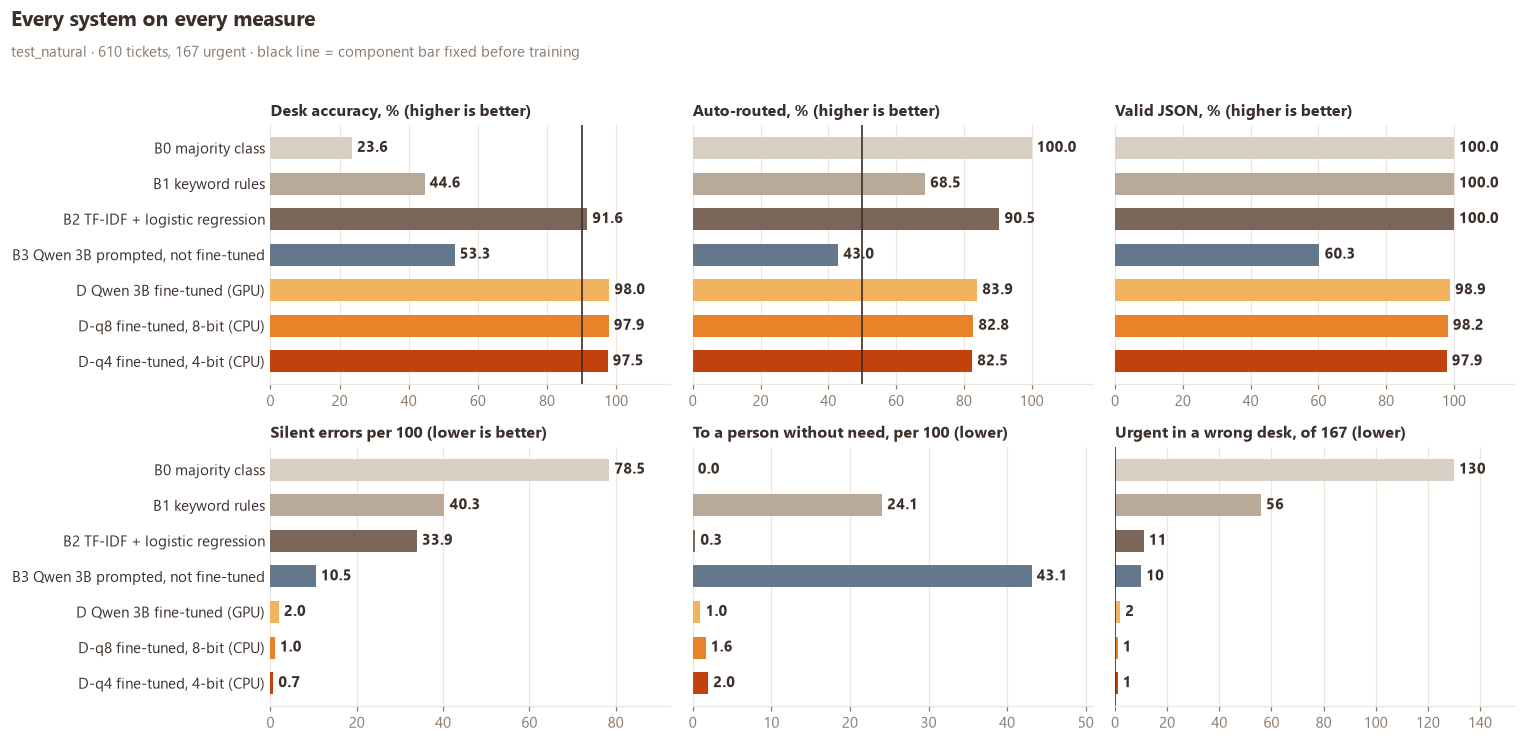

In [7]:
order = NATURAL_SYSTEMS
panels = [
    ("Desk accuracy, % (higher is better)", lambda s: 100 * nat[s]["desk_accuracy"], 90, "{:.1f}"),
    ("Auto-routed, % (higher is better)", lambda s: 100 * nat[s]["auto_routed_rate"], 50, "{:.1f}"),
    ("Valid JSON, % (higher is better)", lambda s: 100 * nat[s]["valid_json_rate"], None, "{:.1f}"),
    ("Silent errors per 100 (lower is better)", lambda s: 100 * nat[s]["silent_error_rate"], None, "{:.1f}"),
    ("To a person without need, per 100 (lower)", lambda s: 100 * nat[s]["needless_triage_rate"], None, "{:.1f}"),
    (f"Urgent in a wrong desk, of {n_urgent} (lower)", lambda s: nat[s]["urgent_wrong_desk"] * n_urgent, 0, "{:.0f}"),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.8))
for k, (ax, (title, value, bar, fmt)) in enumerate(zip(axes.flat, panels)):
    viz.hbar(ax, [NAMES[s] for s in order], [value(s) for s in order], [viz.SYSTEM_COLORS[s] for s in order], fmt=fmt)
    if k % 3:
        ax.set_yticklabels([])
    if bar is not None:
        ax.axvline(bar, color=viz.INK, lw=1.1, zorder=3)
    ax.set_title(title, loc="left", fontsize=10.5)
viz.headline(fig, "Every system on every measure", "test_natural · 610 tickets, 167 urgent · black line = component bar fixed before training")
viz.save(fig, "05_scorecard")
plt.show()

### Does the ranking hold across splits?
Silent errors per 100 tickets on the three splits. `val` is the selection view (same writer model as `train`); the two test splits were written by another model and read once. B0 and B1 have no validation export, so their val bar is recomputed here from the same deterministic baselines.

Using local historical prediction file: data\runs\base_val_predictions.csv
Using local historical prediction file: docs\results\d_qwen2.5-3b_full_run_val_predictions.csv
Using local historical prediction file: docs\results\d_q8_full_run_val_predictions.csv
Using local historical prediction file: docs\results\d_q4_full_run_val_predictions.csv


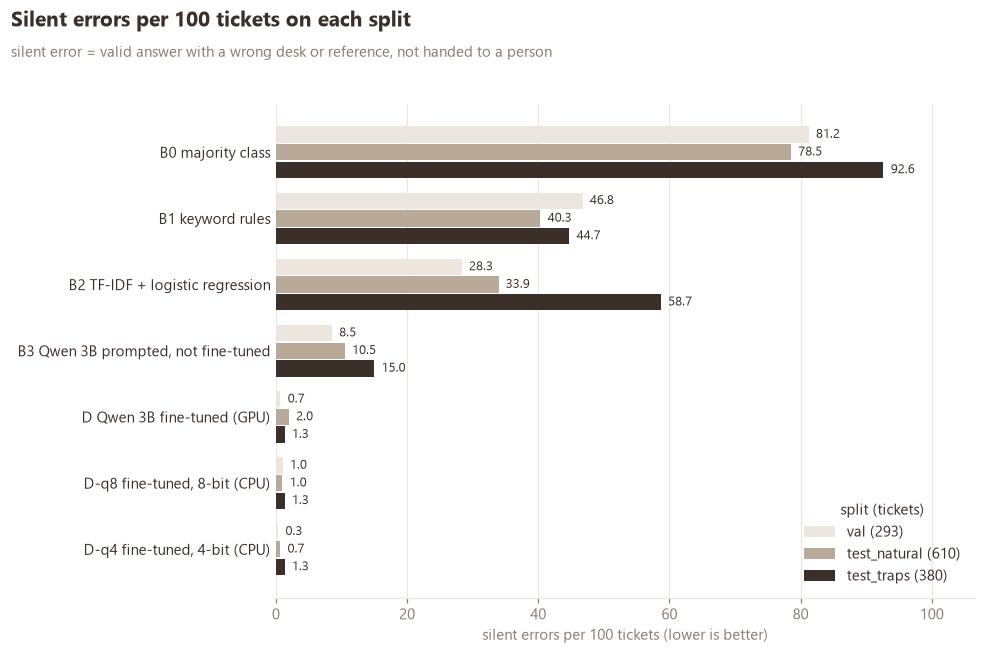

In [8]:
from src.baselines import predict_majority, predict_rules, fit_tfidf, predict_tfidf
val_x, val_y, _ = scoring.load_split(ROOT / "data/dataset/val.csv")
train_x, train_y, _ = scoring.load_split(ROOT / "data/dataset/train.csv")
val_fallback = {"B3": ROOT / "data/runs/base_val_predictions.csv", "D": R / "d_qwen2.5-3b_full_run_val_predictions.csv",
                "D-q8": R / "d_q8_full_run_val_predictions.csv", "D-q4": R / "d_q4_full_run_val_predictions.csv"}
val_raw = {"B0": predict_majority(train_y, val_x), "B1": predict_rules(val_x), "B2": predict_tfidf(fit_tfidf(train_x, train_y, 10.0), val_x)}
val_raw |= {s: _tracking.load_predictions(ROOT, s, "val", p, val_x) for s, p in val_fallback.items()}
by_split = {
    "val (293)": [100 * scoring.score(val_y, val_raw[s])["silent_error_rate"] if val_raw.get(s) is not None else np.nan for s in order],
    "test_natural (610)": [100 * nat[s]["silent_error_rate"] for s in order],
    "test_traps (380)": [100 * trap[s]["silent_error_rate"] if s in trap else np.nan for s in order],
}
fig, ax = plt.subplots(figsize=(9, 6))
viz.grouped_hbar(ax, [NAMES[s] for s in order], by_split, {"val (293)": viz.GRID, "test_natural (610)": viz.NEUTRAL, "test_traps (380)": viz.INK})
ax.legend(loc="lower right", title="split (tickets)")
ax.set_xlabel("silent errors per 100 tickets (lower is better)")
viz.headline(fig, "Silent errors per 100 tickets on each split", viz.SILENT)
viz.save(fig, "05_silent_by_split")
plt.show()

## 5. Verdict: one table
Latency from the CPU run on `test_natural` (Intel Xeon, 8 vCPU); monthly cost with the assumptions of Journal 4. B3 and D both need the same 3B model on a GPU, so they share the T4 endpoint scenario.

In [9]:
tn = json.loads((R / "d_compact_test_natural_timings.json").read_text(encoding="utf-8"))
monthly = {"B0": 0, "B1": 0, "B2": 0, "B3": 255, "D": 255,
           "D-q8": round(tn["q8"]["seconds_mean"] * 36_000 * 0.00008), "D-q4": round(tn["q4"]["seconds_mean"] * 36_000 * 0.00008)}
REPORT_SYSTEMS = [s for s in NATURAL_SYSTEMS if s in TRAP_SYSTEMS]
verdict = pd.DataFrame({
    "silent errors / 100 (natural)": {s: 100 * nat[s]["silent_error_rate"] for s in REPORT_SYSTEMS},
    "silent errors / 100 (traps)": {s: 100 * trap[s]["silent_error_rate"] for s in REPORT_SYSTEMS},
    "urgent in a wrong desk": {s: nat[s]["urgent_wrong_desk"] for s in NATURAL_SYSTEMS},
    "to a person w/o need / 100": {s: 100 * nat[s]["needless_triage_rate"] for s in NATURAL_SYSTEMS},
    "severity score": {s: nat[s]["severity_score"] for s in NATURAL_SYSTEMS},
    "s / ticket (CPU)": {"D-q8": tn["q8"]["seconds_mean"], "D-q4": tn["q4"]["seconds_mean"]},
    "EUR / month": monthly,
})
verdict.style.format({"silent errors / 100 (natural)": "{:.1f}", "silent errors / 100 (traps)": "{:.1f}", "urgent in a wrong desk": "{:.1%}",
                      "to a person w/o need / 100": "{:.1f}", "severity score": "{:.3f}", "s / ticket (CPU)": "{:.1f}", "EUR / month": "{:.0f}"}, na_rep="-")

,silent errors / 100 (natural),silent errors / 100 (traps),urgent in a wrong desk,to a person w/o need / 100,severity score,s / ticket (CPU),EUR / month
B0,78.5,92.6,77.8%,0.0,3.890,-,0
B1,40.3,44.7,33.5%,24.1,2.274,-,0
B2,33.9,58.7,6.6%,0.3,1.666,-,0
B3,10.5,15.0,6.0%,43.1,0.998,-,255
D,2.0,1.3,1.2%,1.0,0.111,-,255
D-q8,1.0,1.3,0.6%,1.6,0.067,8.9,26
D-q4,0.7,1.3,0.6%,2.0,0.054,7.4,21


**Champion: D-q4.** Fewest silent errors and lowest severity on realistic tickets, 0.6 % urgent tickets in a wrong desk, ~2.4 GB of RAM, ~7 s per ticket, ~20 euros a month on CPU. D keeps a small edge on the traps but needs a GPU endpoint at ~255 euros a month.

## 6. Gate G8: registration
The model is registered in the Vertex AI Model Registry: `keelpay-router-json`, ID `7308774847222382592`, alias `qwen3b-lora-q4`, region `europe-west2`. No endpoint is standing (teardown checked).

**Open point for the shared project:** the severity points are assumptions; the euro values of the sizing can be applied to the silent errors and the hand-overs without changing the ranking of the systems.